# pad_model.py

**nn.Embedding**

```python
nn.Embedding(num_embeddings, embedding_dim)
```
- num_embeddings	一共有多少个可学习的向量
- embedding_dim	每个向量包含多少个特征

In [4]:
import torch.nn as nn
embedding = nn.Embedding(5, 3)
print(embedding)

Embedding(5, 3)


相当于创建一个大小为 (5, 3) 的可学习参数矩阵：\
$$
W=
\begin{bmatrix}
0.2 & 0.5 & 0.1 \\
0.3 & 0.7 & 0.4 \\
0.6 & 0.2 & 0.8 \\
0.9 & 0.1 & 0.3 \\
0.4 & 0.6 & 0.5
\end{bmatrix}
$$



**nn.ModuleList**

```python
nn.ModuleList([模块1, 模块2, 模块3, ...])
```
- nn.ModuleList 是 PyTorch 提供的模块容器，用来保存多个神经网络模块。

In [8]:
import torch
import torch.nn as nn

layers = nn.ModuleList([
    nn.Linear(10, 20),
    nn.ReLU(),
    nn.Linear(20, 5)
])
layers[0]  # 第一个 Linear
layers[1]  # ReLU
layers[2]  # 第二个 Linear

Linear(in_features=20, out_features=5, bias=True)

In [11]:
x = torch.randn(4, 10)
print(x)
for layer in layers:
    x = layer(x)

print(x.shape)
# torch.Size([4, 5])

tensor([[-1.2761, -0.1056,  1.0741, -0.2322,  1.3011,  0.8206, -0.1458, -1.0610,
          1.0474,  0.4802],
        [-0.8713, -0.4831, -1.4231, -0.4473,  0.3168,  0.5369,  0.2995,  0.1689,
          0.3345,  0.9250],
        [-0.8443, -0.8692, -0.4877, -1.1428, -0.2245,  0.4372,  0.2757, -1.9030,
          0.0595,  0.9781],
        [ 2.0273,  0.4505, -0.6299,  1.2605, -0.3798, -1.3365,  0.7510,  0.4388,
          0.9737, -0.5831]])
torch.Size([4, 5])


| 特性 | nn.ModuleList | nn.Sequential |
| ---- | ------------- | ------------ |
| 保存多个网络模块 | 支持 | 支持 |
| 自动依次执行 | 不支持 | 支持 |
| 可以索引访问 | 支持 | 支持 |
| 可以使用 \|for 循环 | 支持 | 支持 |
| 适合复杂网络结构 | 更灵活 | 适合顺序连接 |

**enumerate**

```python
enumerate(iterable, start=0)
```
其中：
- iterable：可迭代对象，例如列表、元组、ModuleList。
- start：索引的起始值，默认是 0。

In [1]:
names = ["张三", "李四", "王五"]

for i, name in enumerate(names):
    print(i, name)

0 张三
1 李四
2 王五


原文：
```python
for i, refine in enumerate(self._trajectory_head):
    bev_feature, proposal_list = refine(
        bev_feature, proposal_list, image_feature
    )
    #其中：bev_feature, proposal_list, image_feature是传入的参数
```

# navsim相关概念

**self.poses_num**

```python
self.poses_num = config.num_poses
```
- poses_num 表示预测轨迹中的位姿点数量（Number of Poses）。简单来说，就是模型预测未来车辆运动轨迹时，需要预测多少个未来位置。

假设自动驾驶模型需要预测未来 4 秒的轨迹，每隔 0.5 秒预测一个位置。

那么：
$$
N=\frac{4}{0.5}=8
$$
即：
poses_num = 8;模型需要预测未来 8 个位姿点。

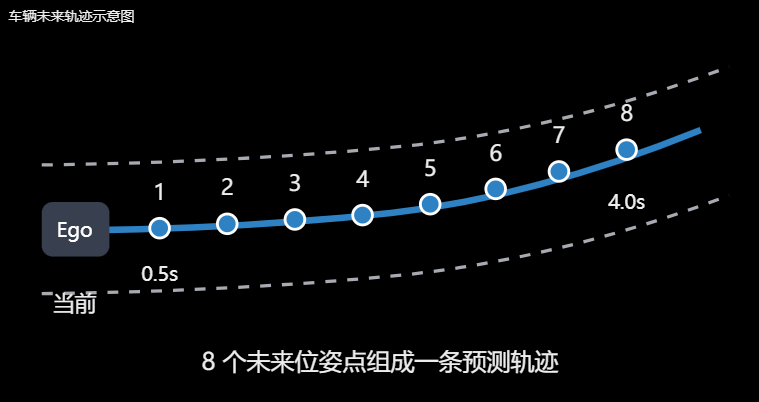

每个轨迹点通常包含三个状态：$p_t=(x_t,y_t,\theta_t)$

其中：
- $x_t$：车辆未来的纵向位置。
- $y_t$：车辆未来的横向位置。
- $\theta_t$：车辆未来的航向角。
这也对应你代码中的：**self.state_size = 3**

**proposal_num and tf_d_model**

源代码：
```python
self.poses_num = config.num_poses

self.init_feature = nn.Embedding(
    self.poses_num * config.proposal_num,
    config.tf_d_model
)
```
| 参数 | 含义 |
| ---- | ---- |
| poses_num | 每条轨迹预测多少个未来位姿点 |
| proposal_num | 生成多少条候选轨迹 |
| tf_d_model | 每个位姿对应的特征向量维度 |


# 段落解析

```python
if self.traj_bev:
    self.Bev_refiner = Bev_refiner(
        config,
        config.proposal_num,
        self.poses_num,
        config.traj_proposal_query
    )
```